  Unsupervised Learning for Image Classification

  Universidad de los Andes

  John Morrill
  
  February 23, 2025


### **1. Importing Required Libraries**

In [ ]:
!pip install nbconvert

In [ ]:
!jupyter nbconvert --to html /Microproyecto1_John_Morrill.ipynb

[NbConvertApp] Converting notebook /Microproyecto1_John_Morrill.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 12 image(s).
[NbConvertApp] Writing 2944190 bytes to /Microproyecto1_John_Morrill.html


In [ ]:
!pip install scikit-learn-extra
!pip install pyclustering
!pip install kneed

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import time
from PIL import Image
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from kneed import KneeLocator
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.spatial.distance import cdist
from sklearn.pipeline import Pipeline
from google.colab import data_table
from sklearn.preprocessing import FunctionTransformer

In [ ]:
glb_random_state = 42
cluster_range = []

k_min = 2
k_max = 10
glb_cluster_range = range(k_min, k_max+1)

In [ ]:
def print_seconds(inicio, fin):
    duracion = fin - inicio
    return f"Tiempo de ejecución: {duracion:.2f} segundos"

### **2. Data Loading**

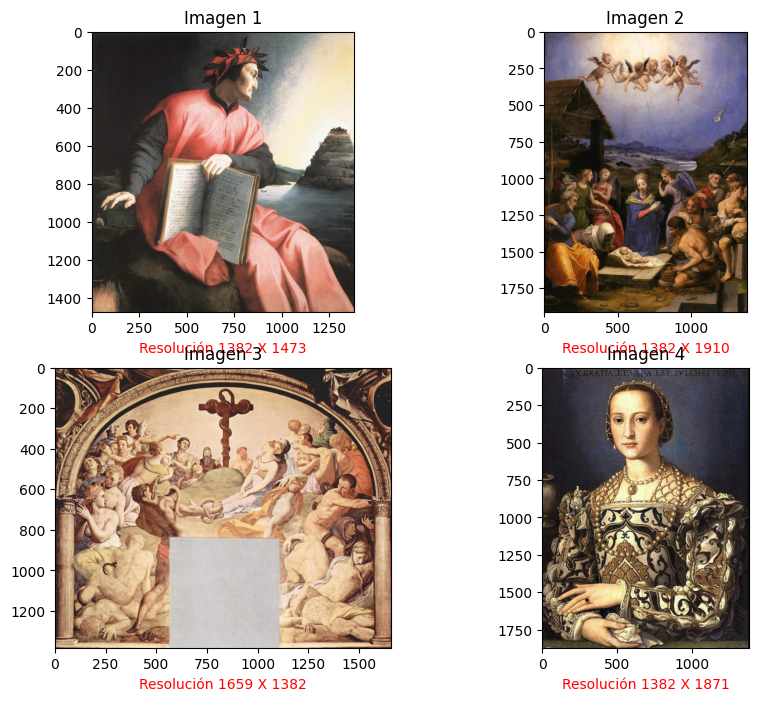

In [ ]:
list_images = []
list_images_routes = []
download_folder = "Wikiart_images"
full_image_path = os.path.join(download_folder, "agnolo-bronzino_allegorical-portrait-of-dante-1530.jpg")
list_images_routes.append(full_image_path)
list_images.append(Image.open(full_image_path))

full_image_path = os.path.join(download_folder, "agnolo-bronzino_adoration-of-the-shepherds.jpg")
list_images_routes.append(full_image_path)
list_images.append(Image.open(full_image_path))

full_image_path = os.path.join(download_folder, "agnolo-bronzino_adoration-of-the-cross-with-the-brazen-serpent.jpg")
list_images_routes.append(full_image_path)
list_images.append(Image.open(full_image_path))

full_image_path = os.path.join(download_folder, "agnolo-bronzino_eleonora-da-toledo-1562.jpg")
list_images_routes.append(full_image_path)
list_images.append(Image.open(full_image_path))


fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(list_images[i])
    width, height = list_images[i].size
    ax.set_title(f"Image {i+1}")
    ax.set_xlabel(f"Resolucion {width} X {height}")
    ax.xaxis.label.set_color('red')

plt.show()

Resoluciónes son differentes para todos los imagenes.


## 1. Reduce the image resolution without losing quality or color.

The following procedure outlines the steps to obtain a resized image:



*   `cv.imread` allows the function to read the image from a given path.
*   `Numpy.ndarray` returns a shape consisting of height, width, and channels.
*   `Get_rgb_color` is used to read the image and obtain a list of RGB colors.
*   `resize_image` is a function that resizes images so the algorithm runs faster. In clustering algorithms, this step is necessary because processing takes longer without resizing. You can skip this step if you do not want to lose information; however, generating the clusters will take more time.




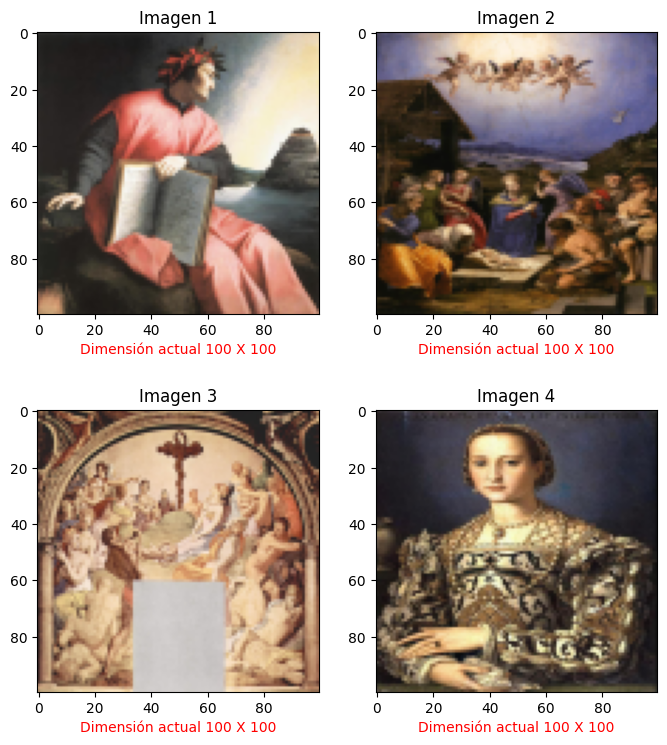

In [ ]:
def readImage(ruta):
    return cv.imread(ruta)

def resize_image(image, width, height):
    return cv.resize(image, (width, height), interpolation=cv.INTER_AREA)

def get_rgb_color(image):
    return cv.cvtColor(image, cv.COLOR_BGR2RGB)


list_images_resized = []

ancho_nuevo = 100 #300
alto_nuevo = 100 #200
def custom_resize_image():
    for image_route in list_images_routes:

        img = cv.imread(image_route)
        if img is None:
            print(f"Failed to read image: {image_route}")
            continue  # Skip to next file


        img = get_rgb_color(img) # color original obtenido
        img = resize_image(img, ancho_nuevo, alto_nuevo)
        list_images_resized.append(img)

    fig, axes = plt.subplots(2, 2, figsize=(8, 9))
    for i, ax in enumerate(axes.flat):
        ax.imshow(list_images_resized[i])
        height, width, canales = list_images_resized[i].shape
        ax.set_title(f"Image {i+1}")
        ax.set_xlabel(f"Current Dimensión {width} X {height}") #Canales de color: {canales}
        ax.xaxis.label.set_color('red')

    plt.show()


custom_resize_image()

## 2. Process of flattening and normalizing the images

The image flattening function has two parameters:

*   The value 3 checks each row for maximum values.
*   The value -1 tells NumPy to automatically calculate the required number of rows.


By adding these parameters, we can flatten the image into a pixel matrix:
*   One column per color channel.
*   Each row represents a pixel.

The function creates a list of RGB pixels corresponding to the total number of pixels derived from the image's height and width.
The normalized image function will be used to run trial-and-error algorithms.

In [ ]:
def flatten_images(image):
    return image.reshape(-1, 3)

def normalize_image(image):
    return image / 255.0

def flatten_normalize_resized_images(flatten=True, normalize=True, useScaler=False):
    image_list = list()
    for image_resized in list_images_resized:
        if flatten:
            image_resized = flatten_images(image_resized)

        if useScaler:
            scaler = StandardScaler()
            image_resized = scaler.fit_transform(image_resized)
        elif normalize:
            image_resized = normalize_image(image_resized)

        image_list.append(image_resized)
    return image_list

In [ ]:
transformed_images = flatten_normalize_resized_images(flatten=True, normalize=True)
transformed_images[0]



array([[0.19215686, 0.18823529, 0.18039216],
       [0.18431373, 0.18431373, 0.17647059],
       [0.18039216, 0.18039216, 0.17254902],
       ...,
       [0.80392157, 0.54901961, 0.44705882],
       [0.83137255, 0.60392157, 0.51764706],
       [0.71372549, 0.51764706, 0.43137255]])

## 3. Image segmentation

# Two methods are required to segment the images: the elbow method and the silhouette method.


*   The elbow method evaluates a plot to identify the most distinct "elbow" pattern. In this context, an "elbow pattern" refers to a point on the graph where the inertia score begins to decrease at a slower rate, resembling the bend of an elbow. To generate the plot, we must calculate the inertia score, which uses the sum of squared distances between data points to assess how well the data is clustered. A high score indicates that the data is tightly clustered, whereas a low score indicates the opposite. The inertia score is plotted to determine the optimal number of clusters (K).
*   By using the silhouette method, we can determine the optimal number of clusters for our color palette, ensuring the accuracy of our study.




In [ ]:
def silhouette_elbow_function(X, model, k_min, k_max):
    scores = []
    inertias = []
    cluster_range = range(k_min, k_max+1)
    for i in range(k_min, k_max+1):
        if model == "kmeans":
            model_k = KMeans(n_clusters=i, max_iter=300, n_init=10, random_state=glb_random_state)
        else:
            model_k = KMedoids(n_clusters=i, max_iter=300, random_state=glb_random_state, metric='euclidean')
        model_k.fit(X)

        try:
            score = silhouette_score(X, model_k.labels_)
            scores.append(score)
        except Exception as e:
            print(f"An error occurred: {e}")
            scores.append(0) # This shouldn't happen

        inertias.append(model_k.inertia_)

    return range(k_min,k_max+1), scores, inertias

### Execution time of the K-means algorithm.


In [ ]:
k_min = 2
k_max = 10
kmeans_time_execution = []
k_ranges = []
k_scores = []
k_inertias = []
for transformed_image in transformed_images:
    # obtain the silhouette coefficient and inertia
    inicio = time.time()

    k, scores, inertias = silhouette_elbow_function(transformed_image, "kmeans", k_min, k_max)
    k_ranges.append(k)
    k_scores.append(scores)
    k_inertias.append(inertias)

    fin = time.time()
    kmeans_time_execution.append(print_seconds(inicio, fin))

In [ ]:
kmeans_time_execution

['Tiempo de ejecución: 30.17 segundos',
 'Tiempo de ejecución: 15.92 segundos',
 'Tiempo de ejecución: 15.56 segundos',
 'Tiempo de ejecución: 16.47 segundos']

The image execution times, from fastest to slowest, are:

1.   Image 3 time = 14.73
2.   Image 4 time = 14.79
3.   Image 2 time = 15.03
4.   Image 1 time = 20.21

### K-means Elbow and Silhouette plots with clusters.

In [ ]:
if cluster_range == []:
    cluster_range = range(k_min, k_max+1)
cluster_range_np = np.array(cluster_range)

In [ ]:
elbow_knee = []
silhouette_knee = []

In [ ]:
k_inertias_np = np.array(k_inertias)
for i, inertia_np in enumerate(k_inertias_np):
    knee_locator = KneeLocator(cluster_range_np, inertia_np, curve="convex", direction="decreasing")
    optimal_k_elbow = knee_locator.knee
    elbow_knee.append(optimal_k_elbow)
    print(f"Elbow K imagen {i+1}: {optimal_k_elbow}")

Elbow K imagen 1: 4
Elbow K imagen 2: 5
Elbow K imagen 3: 4
Elbow K imagen 4: 4


In [ ]:
k_scores_np = np.array(k_scores)
for i, single_score in enumerate(k_scores_np):
    optimal_k_silhouette = cluster_range[np.argmax(single_score)]
    silhouette_knee.append(optimal_k_silhouette)
    print(f"Silhouette K image {i+1}: {optimal_k_silhouette}")

Silhouette K imagen 1: 2
Silhouette K imagen 2: 2
Silhouette K imagen 3: 2
Silhouette K imagen 4: 2


For the four images, the silhouette score is 2. For the elbow analysis, images 1, 3, and 4 have scores of 4, which are reliable. Image 2 has a score of 5, which is less reliable.

Below are the graphs for K-means:

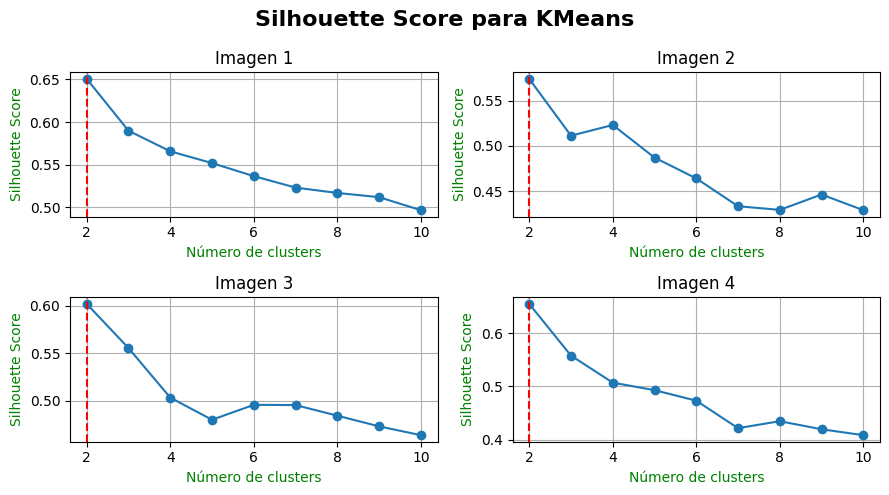

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5))
for i, ax in enumerate(axes.flat):
    ax.plot(k_ranges[i], k_scores[i], marker='o')
    ax.set_title(f"Image {i+1}")
    ax.set_xlabel('Number of Clusters')
    ax.xaxis.label.set_color('green')
    ax.set_ylabel('Silhouette Score')
    ax.yaxis.label.set_color('green')
    ax.axvline(silhouette_knee[i], color='red', linestyle='--', label=f'Silhouette Point: {silhouette_knee[i]}')
    ax.grid()

fig.suptitle("KMeans Silhouette Score", fontsize=16, color='black', fontweight='bold')
plt.tight_layout()
plt.show()

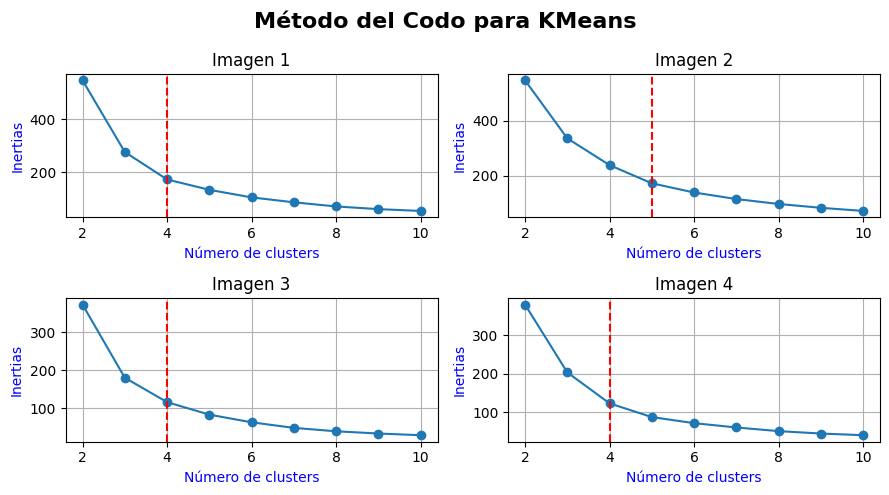

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5))
for i, ax in enumerate(axes.flat):
    ax.plot(k_ranges[i], k_inertias[i], marker='o')
    ax.set_title(f"Image {i+1}")
    ax.set_xlabel('Number of Clusters')
    ax.xaxis.label.set_color('blue')
    ax.set_ylabel('Inertias')
    ax.yaxis.label.set_color('blue')
    ax.axvline(elbow_knee[i], color='red', linestyle='--', label=f'Elbow Point: {elbow_knee[i]}')
    ax.grid()

fig.suptitle("Elbow Method for K-Means", fontsize=16, color='black', fontweight='bold')
plt.tight_layout()
plt.show()

### K-means algorithm execution time.

In [ ]:
from pyclustering.cluster.kmedoids import kmedoids
import warnings
warnings.filterwarnings("ignore")

In [ ]:
k_min = 2
k_max = 10
kmedoids_time_execution = []
k_ranges_medo = []
k_scores_medo = []
k_inertias_medo = []
for transformed_image in transformed_images:
    inicio = time.time()

    k, scores, inertias = silhouette_elbow_function(transformed_image, "kmedoids", k_min, k_max)
    k_ranges_medo.append(k)
    k_scores_medo.append(scores)
    k_inertias_medo.append(inertias)

    fin = time.time()
    kmedoids_time_execution.append(print_seconds(inicio, fin))

In [ ]:
kmedoids_time_execution

['Tiempo de ejecución: 74.28 segundos',
 'Tiempo de ejecución: 64.55 segundos',
 'Tiempo de ejecución: 76.99 segundos',
 'Tiempo de ejecución: 85.78 segundos']

The image execution times from fastest to slowest are:

1.   Image 2 time = 57.35
2.   Image 3 time = 68.44
3.   Image 1 time = 70.87
4.   Image 4 time = 79.95

### K-Medoids Elbow and Silhouette plots with clusters.

In [ ]:
elbow_knee_kmedo = []
silhouette_knee_kmedo = []

In [ ]:
k_inertias_np = np.array(k_inertias_medo)
for i, inertia_np in enumerate(k_inertias_np):
    knee_locator = KneeLocator(cluster_range_np, inertia_np, curve="convex", direction="decreasing")
    optimal_k_elbow = knee_locator.knee
    elbow_knee_kmedo.append(optimal_k_elbow)
    print(f"Elbow K-medoides - Image {i+1}: {optimal_k_elbow}")

Elbow K-medoides - Imagen 1: 4
Elbow K-medoides - Imagen 2: 5
Elbow K-medoides - Imagen 3: 5
Elbow K-medoides - Imagen 4: 5


In [ ]:
k_scores_np = np.array(k_scores_medo)
for i, single_score in enumerate(k_scores_np):
    optimal_k_silhouette = cluster_range[np.argmax(single_score)]
    silhouette_knee_kmedo.append(optimal_k_silhouette)
    print(f"Silhouette K-medoides - Image {i+1}: {optimal_k_silhouette}")

Silhouette K-medoides - Imagen 1: 2
Silhouette K-medoides - Imagen 2: 2
Silhouette K-medoides - Imagen 3: 2
Silhouette K-medoides - Imagen 4: 2


For the four images, the silhouette score is 2. For the elbow analysis, images 2, 3, and 4 have scores of 5, which are reliable. Image 1 has a score of 4, which is less reliable.



Below are the graphs for K-means:

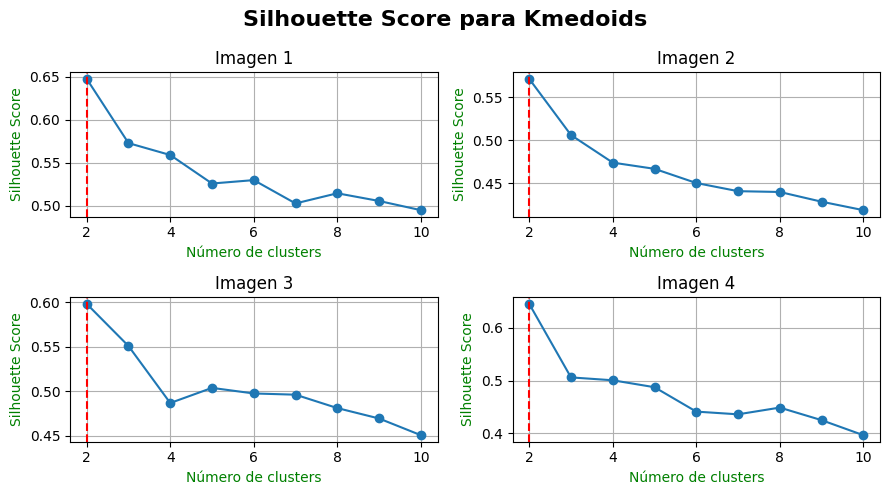

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5))
for i, ax in enumerate(axes.flat):
    ax.plot(k_ranges_medo[i], k_scores_medo[i], marker='o')
    ax.set_title(f"Image {i+1}")
    ax.set_xlabel('Number of Clusters')
    ax.xaxis.label.set_color('green')
    ax.set_ylabel('Silhouette Score')
    ax.yaxis.label.set_color('green')
    ax.axvline(silhouette_knee_kmedo[i], color='red', linestyle='--', label=f'Silhouette Point: {silhouette_knee_kmedo[i]}')
    ax.grid()

fig.suptitle("Silhouette Score for Kmedoids", fontsize=16, color='black', fontweight='bold')
plt.tight_layout()
plt.show()

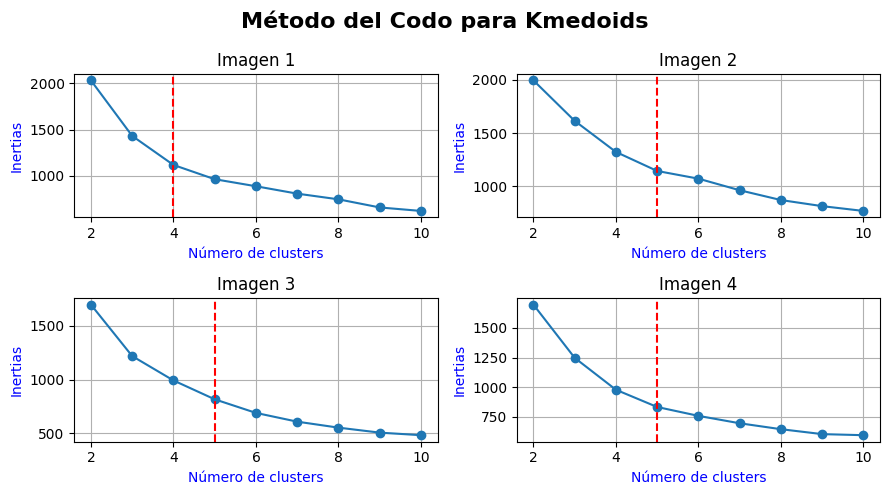

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5))
for i, ax in enumerate(axes.flat):
    ax.plot(k_ranges_medo[i], k_inertias_medo[i], marker='o')
    ax.set_title(f"Image {i+1}")
    ax.set_xlabel('Number of Clusters')
    ax.xaxis.label.set_color('blue')
    ax.set_ylabel('Inertias')
    ax.yaxis.label.set_color('blue')
    ax.axvline(elbow_knee_kmedo[i], color='red', linestyle='--', label=f'Elbow Point: {elbow_knee_kmedo[i]}')
    ax.grid()

fig.suptitle("Elbow Method for K-Means", fontsize=16, color='black', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
dfzxx = pd.DataFrame(list_images)
#dfzxx['concatenado'] = dfzxx.iloc[:, 0] + ' - ' + dfzxx.iloc[:, 4]
array_concatenado = dfzxx.to_numpy()

### Hyperparameter K Selection for K-means and K-medoids

The optimal number of clusters is determined by comparing results. We will use the K-means and K-medoids algorithms.

In [ ]:
optimal_clusters = {
        "Image Route": list_images_routes,
        "Elbow Kmeans": elbow_knee,
        "Silhouette Kmeans": silhouette_knee,
        "Elbow Kmedoids": elbow_knee_kmedo,
        "Silhouette Kmedoids": silhouette_knee_kmedo,
    }
df_resultado = pd.DataFrame(optimal_clusters)
df_resultado

,Ruta imagen,Elbow Kmeans,Silhouette Kmeans,Elbow Kmedoids,Silhouette Kmedoids
0,Wikiart_images/agnolo-bronzino_allegorical-por...,4,2,4,2
1,Wikiart_images/agnolo-bronzino_adoration-of-th...,5,2,5,2
2,Wikiart_images/agnolo-bronzino_adoration-of-th...,4,2,5,2
3,Wikiart_images/agnolo-bronzino_eleonora-da-tol...,4,2,5,2


In [ ]:
ancho_nuevo = 100 #300
alto_nuevo = 100 #200
max_iteraciones = 300

def transformar_imagen(ruta_imagen):

    # 1. Read the route image
    image = cv.imread(ruta_imagen)
    # 2. get the RGB color of the original image
    image_rgb = get_rgb_color(image)
    # 3. Resize the Image
    image_resized = resize_image(image_rgb, ancho_nuevo, alto_nuevo)
    # 4. Flatten Image
    image_reshape = flatten_images(image_resized)
    # 5. Normalize Image
    image_normalize = normalize_image(image_reshape)

    return image, image_resized, image_reshape, image_normalize


def ejecutar_algoritmo_agrupacion(model, image_normalize, clusters_codo):
    if model == "kmeans":
        model_partition = KMeans(n_clusters=clusters_codo, max_iter=max_iteraciones, n_init=10, random_state=glb_random_state)
    else:
        model_partition = KMedoids(n_clusters=clusters_codo, max_iter=max_iteraciones, random_state=glb_random_state, metric='euclidean') ## 'pam' is more accurate.  method='pam' superdelay, with 16 clusters 20 min, with 4 clusters:

    model_partition.fit(image_normalize)
    score_silueta = 0
    try:
        score_silueta = silhouette_score(image_normalize, model_partition.labels_)
    except Exception as e:
        print(f"An error occurred: {e}")

    inertias = model_partition.inertia_
    centroides = model_partition.cluster_centers_
    labels = model_partition.labels_
    return centroides, inertias, score_silueta, labels

In [ ]:
image, image_resized, image_reshape, image_normalize = transformar_imagen(list_images_routes[1])

Number of clusters allocated to execute a given function.

In [ ]:
clusters_codo_kmeans = 4
centroides, inertias, score_silueta, labels = ejecutar_algoritmo_agrupacion("kmeans", image_normalize, clusters_codo_kmeans)

After resizing, we determine the size for the image.

In [ ]:
image_resized.shape

(100, 100, 3)

The image normalization size.

In [ ]:
image_normalize.shape

(10000, 3)

We use centroids to segment the image.

In [ ]:
img_segmented = centroides[labels]*255
img_segmented = img_segmented.reshape(image_resized.shape)

Difference with Kmeans

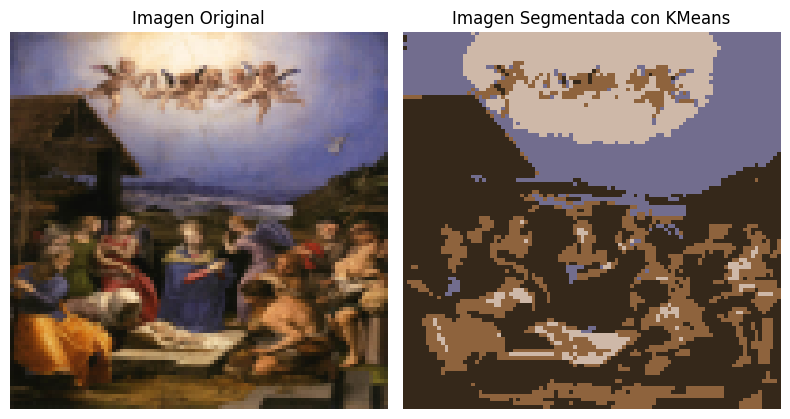

In [ ]:
plt.figure(figsize=(8, 9))

plt.subplot(1, 2, 1)
plt.title('Original Image')
plt.imshow(image_resized)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Segmented KMeans Image')
plt.imshow(img_segmented.astype(np.uint8))
plt.axis('off')

plt.tight_layout()
plt.show()

Process for obtaining the palette.

In [ ]:
def show_centroid_colors(centroids):
    palette = np.expand_dims(centroids, axis=0)
    num = np.arange(0,len(centroids))
    plt.figure(figsize=(4, 4))
    plt.xticks(num)
    plt.yticks([])
    plt.imshow(palette)

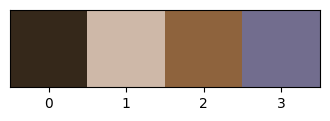

In [ ]:
show_centroid_colors(centroides)

Now with Kmedoids

In [ ]:
clusters_codo_kmed = 5
centroides_kmed, inertias_kmed, score_silueta_kmed, labels_kmed = ejecutar_algoritmo_agrupacion("kmedoides", image_normalize, clusters_codo_kmed)

Difference with Kmedoids

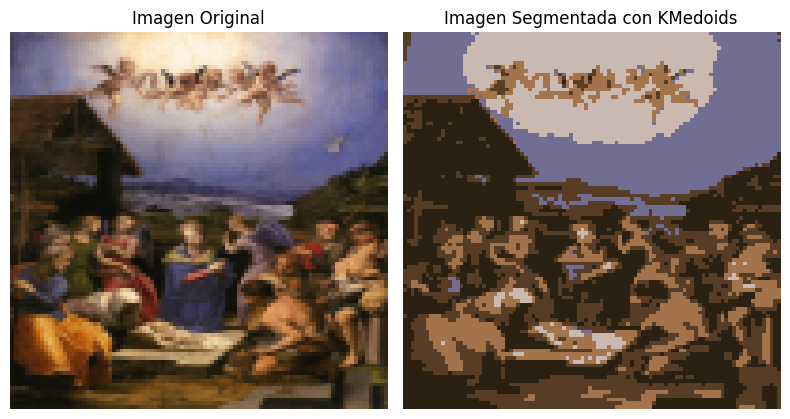

In [ ]:
img_segmented = centroides_kmed[labels_kmed]*255
img_segmented = img_segmented.reshape(image_resized.shape)
plt.figure(figsize=(8, 9))

plt.subplot(1, 2, 1)
plt.title('Original Image')
plt.imshow(image_resized)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Segmented KMedoids Image')
plt.imshow(img_segmented.astype(np.uint8))
plt.axis('off')

plt.tight_layout()
plt.show()

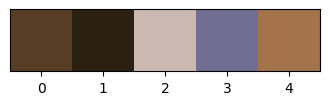

In [ ]:
show_centroid_colors(centroides_kmed)

### Dimensionality reduction with PCA

Dimensionality is reduced when using PCA. You can observe the explained variance.

In [ ]:
pca = PCA(n_components=3)
pca_fit = pca.fit(image_normalize)
pixels_pca = pca_fit.transform(image_normalize)

In [ ]:
pixels_pca

array([[-0.0665531 ,  0.13505219, -0.01057302],
       [-0.04400323,  0.1346456 , -0.00680293],
       [ 0.00355666,  0.14920451, -0.00824049],
       ...,
       [-0.44096726,  0.04867997,  0.02500558],
       [-0.33635705,  0.0204643 ,  0.01221129],
       [-0.24107939,  0.00773421,  0.00795787]])

We Use t-SNE

In [ ]:
tsne = TSNE(n_components=3, random_state=glb_random_state, perplexity=30, verbose=1)
pixels_tsne = tsne.fit_transform(image_normalize)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 10000 samples in 0.011s...
[t-SNE] Computed neighbors for 10000 samples in 0.222s...
[t-SNE] Computed conditional probabilities for sample 1000 / 10000
[t-SNE] Computed conditional probabilities for sample 2000 / 10000
[t-SNE] Computed conditional probabilities for sample 3000 / 10000
[t-SNE] Computed conditional probabilities for sample 4000 / 10000
[t-SNE] Computed conditional probabilities for sample 5000 / 10000
[t-SNE] Computed conditional probabilities for sample 6000 / 10000
[t-SNE] Computed conditional probabilities for sample 7000 / 10000
[t-SNE] Computed conditional probabilities for sample 8000 / 10000
[t-SNE] Computed conditional probabilities for sample 9000 / 10000
[t-SNE] Computed conditional probabilities for sample 10000 / 10000
[t-SNE] Mean sigma: 0.007808
[t-SNE] KL divergence after 250 iterations with early exaggeration: 67.500542
[t-SNE] KL divergence after 1000 iterations: 0.695562


The distribution and t-SNE of the colors will be observed.

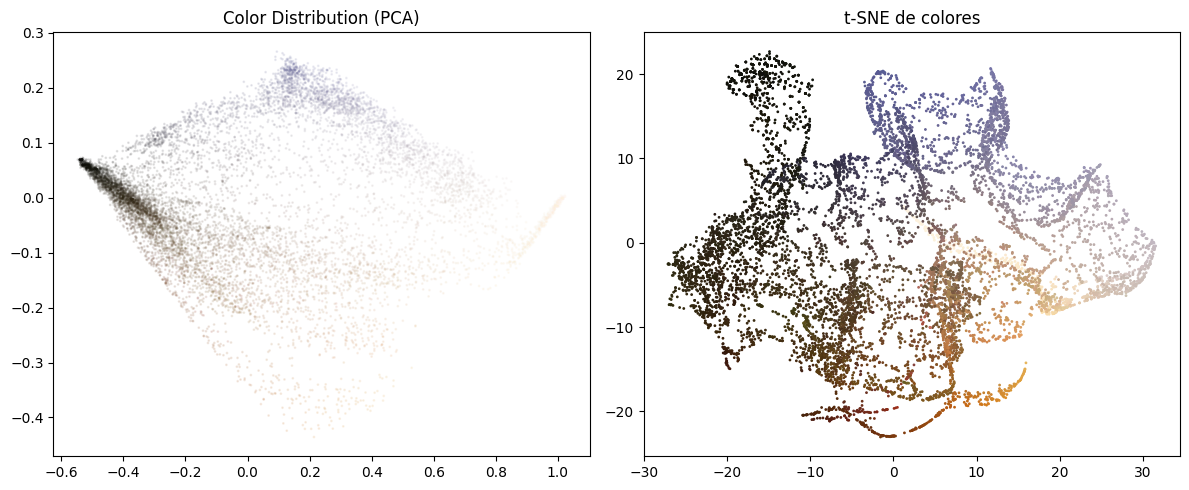

In [ ]:
division_c = image_reshape / 255

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(pixels_pca[:, 0], pixels_pca[:, 1], c=division_c, s=1, alpha=0.1)
plt.title('Color Distribution (PCA)')

plt.subplot(1, 2, 2)
plt.scatter(pixels_tsne[:, 0], pixels_tsne[:, 1], c=division_c, s=1)
plt.title("t-SNE Colors")

plt.tight_layout()
plt.show()

The explained variance.

In [ ]:
sum(pca_fit.explained_variance_ratio_)

1.0

The cumulative sum of the variance.

In [ ]:
cumsum = np.cumsum(pca_fit.explained_variance_ratio_)
cumsum

array([0.90620107, 0.99625995, 1.        ])

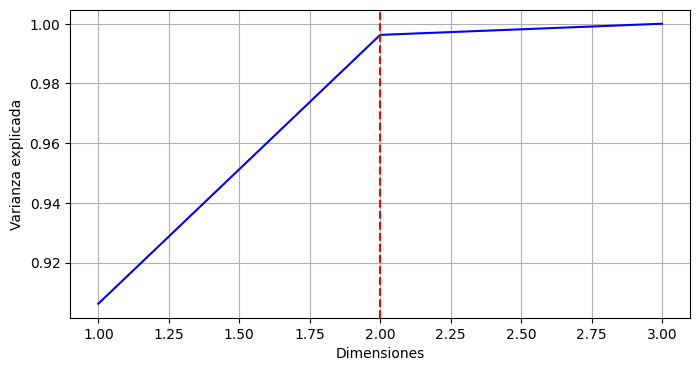

In [ ]:
exp_var = 0.95

plt.figure(figsize=(8, 4))
x = np.arange(1,len(cumsum)+1)
d = np.argmax(cumsum >= exp_var) + 1
plt.plot(x, cumsum, linestyle='-', color='b')
plt.axvline(x=d, color='red', linestyle='--')
plt.xlabel('Dimensions')
plt.ylabel('Explained variance')
plt.grid(True)
plt.show()

In [ ]:
pca = PCA(n_components=exp_var)
x_reduced = pca.fit_transform(image_normalize)

In [ ]:
pca.n_components_

2

### **3. Pipeline**

In [ ]:
scale = StandardScaler()

In [ ]:
image_scaled = image_normalize.copy()
image_scaled = scale.fit_transform(image_scaled)
def create_run_pipeline(image_route):
  steps = [
      ("rgb", FunctionTransformer(get_rgb_color)), # Use the function directly
      ("resize", FunctionTransformer(lambda img: resize_image(img, ancho_nuevo, alto_nuevo))),
      ("Image_reshape", FunctionTransformer(flatten_images)),
      ("normalize", FunctionTransformer(normalize_image)),
      ("scaler", StandardScaler())
  ]

In [ ]:
pipeline = Pipeline(steps)
result = pipeline.fit(image)

result

Pipeline(steps=[('rgb',
                 FunctionTransformer(func=<function get_rgb_color at 0x787ab8f89120>)),
                ('resize',
                 FunctionTransformer(func=<function <lambda> at 0x787ab96a2160>)),
                ('Image_reshape',
                 FunctionTransformer(func=<function flatten_images at 0x787ab8e52200>)),
                ('normalize',
                 FunctionTransformer(func=<function normalize_image at 0x787ab8e525c0>)),
                ('scaler', StandardScaler())])

In [ ]:
def transformar_imagen(ruta_imagen, p_width, p_height):

    image = cv.imread(ruta_imagen) # 1. Read the route image
    image_rgb = get_rgb_color(image) # 2. get the RGB color of the original image
    image_resized = resize_image(image_rgb, p_width, p_height) # 3. Resize the image
    image_reshape = flatten_images(image_resized) # 4. Flatten image
    image_normalize = normalize_image(image_reshape) # 5. Normalize image

    return image, image_rgb, image_resized, image_reshape, image_normalize

def kmeans_function_2(data, krange):
    scores = []
    inertias = []
    centroides = []
    labels = []
    max_iteraciones = 300
    custom_init = 10

    for i in krange:
        model_partition = KMeans(n_clusters=i, max_iter=max_iteraciones, n_init=custom_init, random_state=glb_random_state)
        model_partition.fit(data)
        try:
            score = silhouette_score(data, model_partition.labels_)
            scores.append(score)
        except Exception as e:
            print(f"Error running kmeans_function - silhouette_score: {e}")
            scores.append(0)

        centroides.append(model_partition.cluster_centers_)
        inertias.append(model_partition.inertia_)
        labels.append(model_partition.labels_)
    return centroides, labels, scores, inertias

In [ ]:
def evaluar_codo(k_inertias):
    cluster_range_np = np.array(glb_cluster_range)
    knee_locator = KneeLocator(cluster_range_np, k_inertias, curve="convex", direction="decreasing")
    optimal_k_elbow = knee_locator.knee
    return optimal_k_elbow
def evaluar_silueta(k_scores):
    optimal_k_silhouette = glb_cluster_range[np.argmax(k_scores)]
    return optimal_k_silhouette

In [ ]:
def show_centroid_colors(centroids):
    palette = np.expand_dims(centroids, axis=0)
    num = np.arange(0,len(centroids))
    plt.figure(figsize=(4, 4))
    plt.xticks(num)
    plt.yticks([])
    plt.imshow(palette)

In [ ]:
def visualize_display_charts(image_rgb, image_resized, elbow_inertias, elbow_point, silhouette_scores, silhouette_point, nombreimagen):
    # ax1: Resized image, ax2: elbow, ax3: silhouette, ax4: palette
    fig, (ax0, ax1, ax2, ax3) = plt.subplots(1, 4, figsize=(16, 5))

    # Resized Image
    ax0.imshow(image_rgb)
    ima_h, ima_w, ima_can = image_rgb.shape
    ax0.set_xlabel(f"Original Dimension {ima_w} X {ima_h}")
    ax0.xaxis.label.set_color('purple')

    # Resized Image
    ax1.imshow(image_resized)
    ima_h, ima_w, ima_can = image_resized.shape
    #ax1.set_title(f"Imagen {nombreimagen}")
    ax1.set_xlabel(f"Current Dimension {ima_w} X {ima_h}")
    ax1.xaxis.label.set_color('purple')

    # Elbow Chart
    ax2.plot(glb_cluster_range, elbow_inertias, marker='o')
    #ax2.set_title(f"Imagen {nombreimagen}")
    ax2.set_xlabel('Number of clusters')
    ax2.xaxis.label.set_color('blue')
    ax2.set_ylabel('Elbow Inertias')
    ax2.yaxis.label.set_color('blue')
    ax2.axvline(elbow_point, color='red', linestyle='--', label=f'Elbow Point: {elbow_point}')
    ax2.grid()

    # Silhouette graph
    ax3.plot(glb_cluster_range, silhouette_scores, marker='o')
    #ax3.set_title(f"Imagen {nombreimagen}")
    ax3.set_xlabel('Number of clusters')
    ax3.xaxis.label.set_color('green')
    ax3.set_ylabel('Silhouette Score')
    ax3.yaxis.label.set_color('green')
    ax3.axvline(silhouette_point, color='red', linestyle='--', label=f'Silhouette Point: {silhouette_point}')
    ax3.grid()

    fig.suptitle(f"{nombreimagen}", fontsize=16, color='black', fontweight='bold')
    plt.tight_layout()
    plt.show()

In [ ]:
def ejecutar_PCA(image_normalize):
    pca = PCA(n_components=2)
    pca_fit = pca.fit(image_normalize)
    pixels_pca = pca.fit_transform(image_normalize)

    return pixels_pca, pca_fit.explained_variance_ratio_

In [ ]:
def ejecutar_tsne(image_normalize):
    tsne = TSNE(n_components=2, random_state=glb_random_state, perplexity=30, verbose=0) #verbose=1 to see the progress
    pixels_tsne = tsne.fit_transform(image_normalize)
    return pixels_tsne

In [ ]:
def graficas_espacio_colores(division_c, pixels_pca, pixels_tsne):
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.scatter(pixels_pca[:, 0], pixels_pca[:, 1], c=division_c, s=1, alpha=0.1)
    plt.title('Color Distribution (PCA)')

    if pixels_tsne is not None:
        plt.subplot(1, 2, 2)
        plt.scatter(pixels_tsne[:, 0], pixels_tsne[:, 1], c=division_c, s=1)
        plt.title("t-SNE colors")

    plt.tight_layout()
    plt.show()

In [ ]:
dic_outputs = {}
def capture_output(func, name):
    def wrapper(X):
        dic_outputs[name] = func(X)
        return dic_outputs[name]
    return wrapper

In [ ]:
ancho_nuevo = 100 #300
alto_nuevo = 100 #200
def create_run_pipeline(image_route):
    steps = [
        ("readImage", FunctionTransformer(capture_output(readImage, "readImage"))),
        ("getRGB", FunctionTransformer(capture_output(get_rgb_color, "getRGB"))),
        ("resize", FunctionTransformer(capture_output(lambda img: resize_image(img, ancho_nuevo, alto_nuevo), "resize"))),
        ("reshape", FunctionTransformer(capture_output(flatten_images, "reshape"))),
        ("normalize", FunctionTransformer(capture_output(normalize_image, "normalize")))
    ]
    pipeline = Pipeline(steps)
    result_normalize = pipeline.transform(image_route)
    return result_normalize

In [ ]:
def funcion_ejecutar_todo(images_routes):
    lista_pca_sum = []
    lista_image_normalize = []

    i = 0
    for image_route in images_routes:
        inicio = time.time()

        print(f"Start image transformation: {image_route}")
        image_normalize = create_run_pipeline(image_route)
        image_rgb = dic_outputs["getRGB"]
        image_resized = dic_outputs["resize"]
        image_reshape = dic_outputs["reshape"]
        lista_image_normalize.append(image_normalize)

        print(f"Obtain the best image cluster")
        centroides, labels, score_silueta, inertias = kmeans_function_2(image_normalize, glb_cluster_range)

        print(f"Running metrics")
        elbow_point = evaluar_codo(inertias)
        silueta_point = evaluar_silueta(score_silueta)

        print(f"Generate charts")
        visualize_display_charts(image_rgb, image_resized, inertias, elbow_point, score_silueta, silueta_point, [i])

        print(f"Draw palette")
        print(f"Best elbow point: {elbow_point}")
        show_centroid_colors(centroides[elbow_point-1])
        fin = time.time()
        print(print_seconds(inicio, fin))

        print(f"Execute PCA")
        inicio = time.time()
        pixels_pca, pcasum = ejecutar_PCA(image_normalize)
        lista_pca_sum.append(pcasum)
        fin = time.time()
        print(print_seconds(inicio, fin))

        print(f"Execute TSNE")
        inicio = time.time()
        pixels_tsne = ejecutar_tsne(pixels_pca) #image_normalize
        fin = time.time()
        print(print_seconds(inicio, fin))

        print("Plot color spaces")
        inicio = time.time()
        division_c = normalize_image(image_reshape)
        graficas_espacio_colores(division_c, pixels_pca, pixels_tsne)
        fin = time.time()
        print(print_seconds(inicio, fin))

        i = i + 1

    return lista_pca_sum, lista_image_normalize

Empezar transformación imagen: Wikiart_images/agnolo-bronzino_allegorical-portrait-of-dante-1530.jpg
Obtener el mejor cluster imagen
Corriendo metricas
Ejecutar graficas


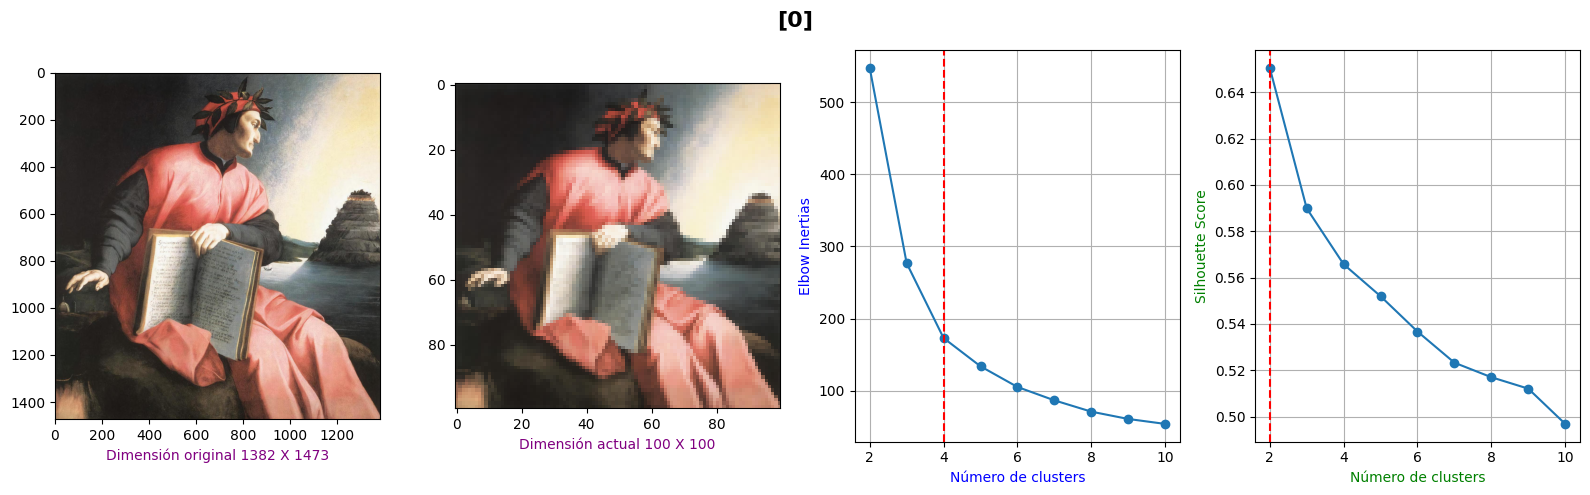

Dibujar paleta
Mejor punto codo: 4
Tiempo de ejecución: 18.72 segundos
Ejecutar PCA
Tiempo de ejecución: 0.00 segundos
Ejecutar TSNE
Tiempo de ejecución: 92.53 segundos
Graficar espacios de colores


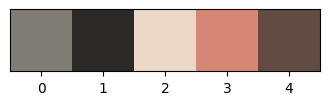

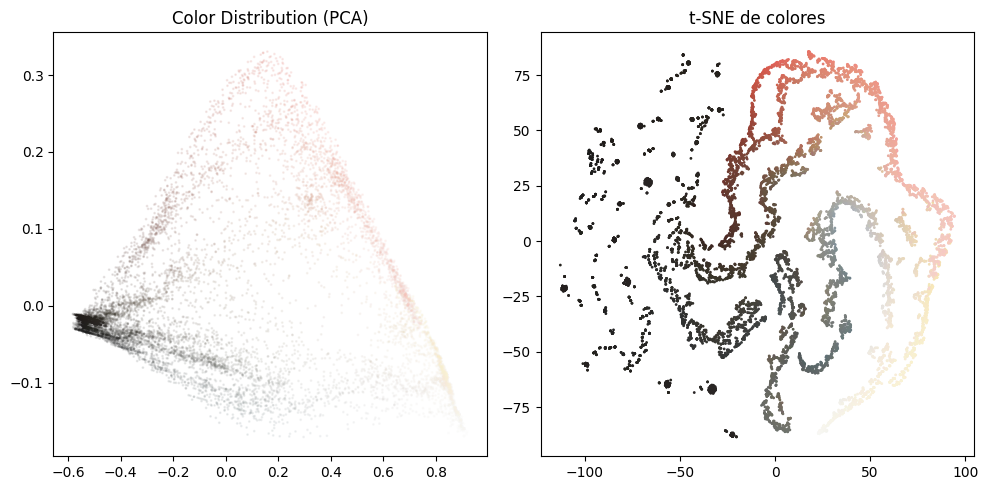

Tiempo de ejecución: 0.72 segundos
Empezar transformación imagen: Wikiart_images/agnolo-bronzino_adoration-of-the-shepherds.jpg
Obtener el mejor cluster imagen
Corriendo metricas
Ejecutar graficas


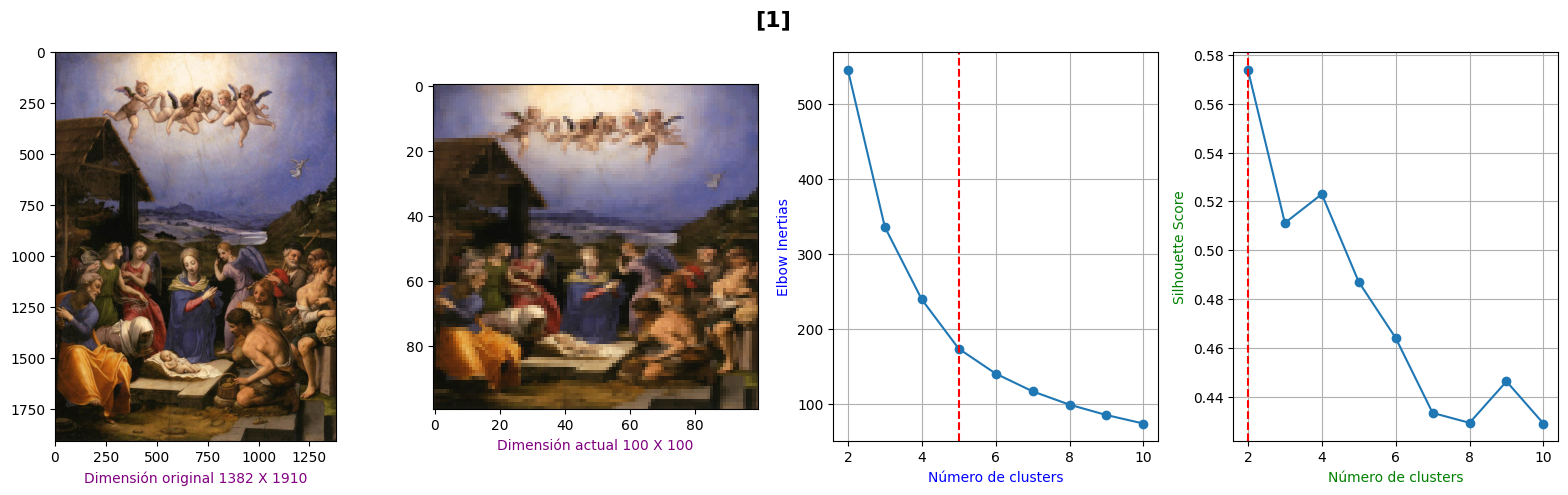

Dibujar paleta
Mejor punto codo: 5
Tiempo de ejecución: 17.73 segundos
Ejecutar PCA
Tiempo de ejecución: 0.00 segundos
Ejecutar TSNE
Tiempo de ejecución: 97.05 segundos
Graficar espacios de colores


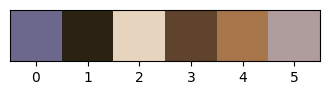

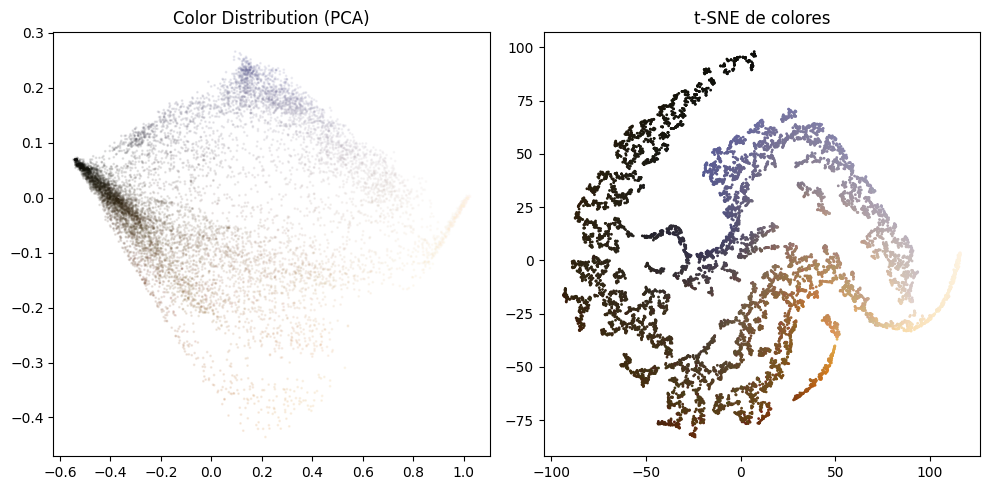

Tiempo de ejecución: 0.75 segundos
Empezar transformación imagen: Wikiart_images/agnolo-bronzino_adoration-of-the-cross-with-the-brazen-serpent.jpg
Obtener el mejor cluster imagen
Corriendo metricas
Ejecutar graficas


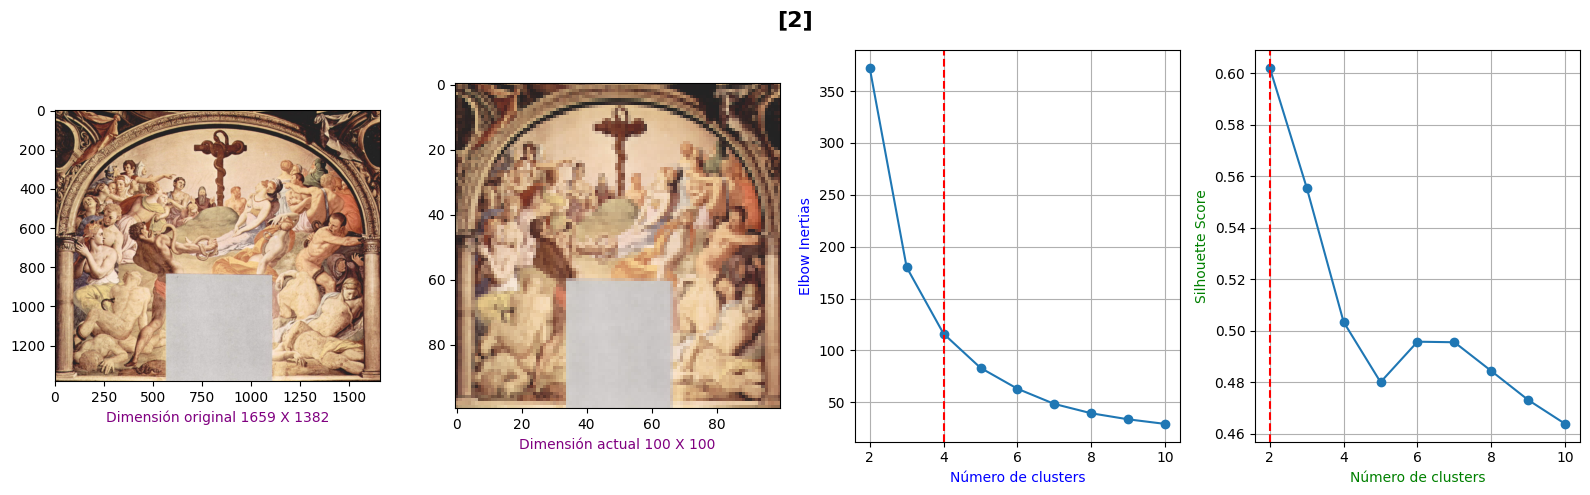

Dibujar paleta
Mejor punto codo: 4
Tiempo de ejecución: 15.82 segundos
Ejecutar PCA
Tiempo de ejecución: 0.00 segundos
Ejecutar TSNE
Tiempo de ejecución: 98.18 segundos
Graficar espacios de colores


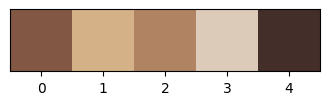

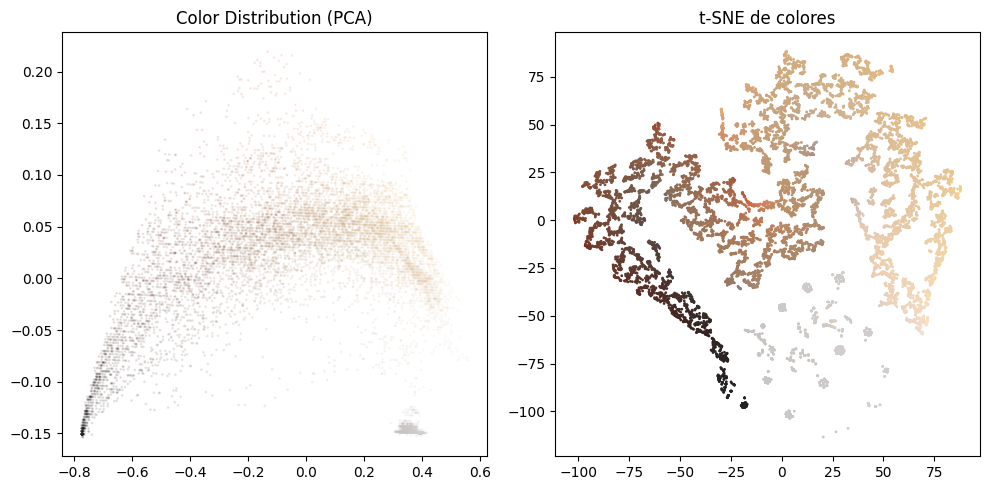

Tiempo de ejecución: 0.75 segundos
Empezar transformación imagen: Wikiart_images/agnolo-bronzino_eleonora-da-toledo-1562.jpg
Obtener el mejor cluster imagen
Corriendo metricas
Ejecutar graficas


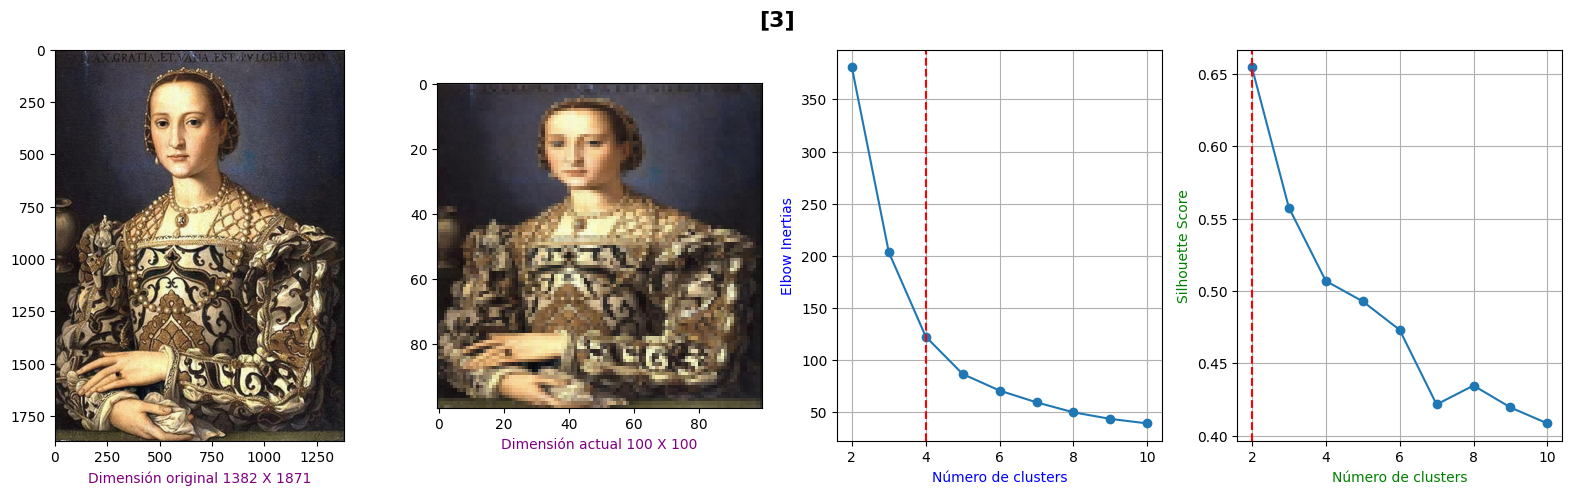

Dibujar paleta
Mejor punto codo: 4
Tiempo de ejecución: 18.66 segundos
Ejecutar PCA
Tiempo de ejecución: 0.00 segundos
Ejecutar TSNE
Tiempo de ejecución: 115.43 segundos
Graficar espacios de colores


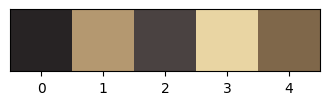

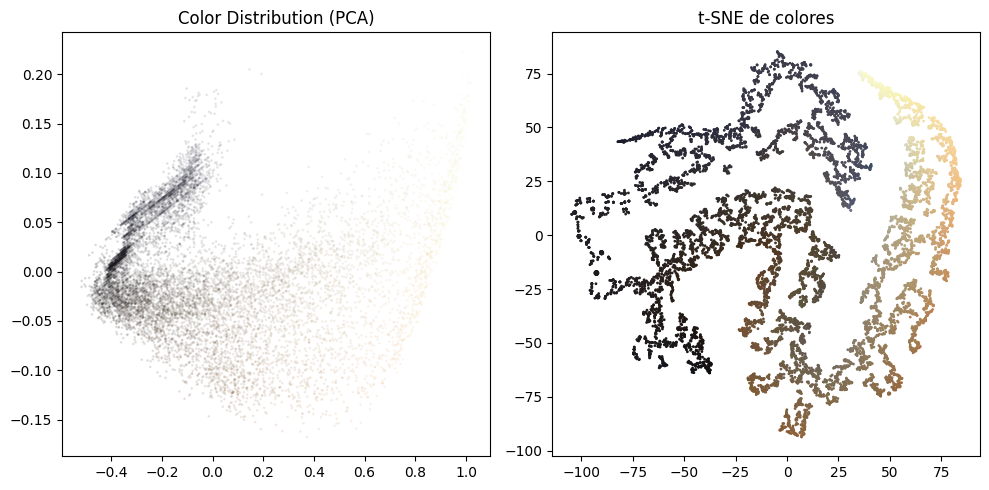

Tiempo de ejecución: 1.27 segundos


In [ ]:
lista_pca_sum, lista_image_normalize = funcion_ejecutar_todo(list_images_routes)

### **4. Conclusions**

Both K-means and K-medoids are methods used for image processing, and both models yield the same silhouette score in this study. K-means has a faster execution time but produces less reliable results than K-medoids. K-medoids is more reliable but has a slower execution time.